# 교차 엔트로피 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week02/cross_entropy/lab/cross_entropy.ipynb)

정답에 건 확률 $q$ 에 대해 벌점 $-\log q$. 슬라이드의 칩 비유를 코드와 진짜 데이터로 확인한다.

- **파트 1**: 칩 비유를 코드로: 벌점 손계산 → scikit-learn `log_loss` 와 맞추기
- **파트 2**: 유방암 진단 데이터: 로지스틱회귀를 교차 엔트로피 vs MSE 로 학습
- **파트 3**: 셰익스피어: 다음 글자에 칩 나눠 걸기 (고르게 vs 세어서)

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

## 파트 1. 칩 비유를 코드로

정답 쪽에 남은 칩 비율이 $q$ 일 때 벌점(비트) $= -\log_2 q$. 슬라이드의 값 (90개 0.15 · 50개 1 · 1개 6.64) 이 나오는지 확인한다.

In [ ]:
def penalty_bits(q):
    """share q (0~1) bet on the right answer -> penalty (bits)"""
    return None             # TODO: -log₂ q

for left in [90, 50, 25, 1]:
    print(f"{left:3d} chips on the answer -> penalty {penalty_bits(left / 100):.2f} bits")
with np.errstate(divide="ignore"):
    print("  0 chips on the answer -> penalty", penalty_bits(0.0), "(bankrupt)")

**예상 결과**

```
 90 chips on the answer -> penalty 0.15 bits
 50 chips on the answer -> penalty 1.00 bits
 25 chips on the answer -> penalty 2.00 bits
  1 chips on the answer -> penalty 6.64 bits
  0 chips on the answer -> penalty inf (bankrupt)
```

실제 학습 코드는 자연로그 $\ln$ 을 쓴다. 이진 분류의 평균 교차 엔트로피:
$$L = -\frac{1}{m}\sum_{i=1}^{m} \big[y_i \ln \hat y_i + (1-y_i)\ln(1-\hat y_i)\big]$$

In [ ]:
def binary_ce(y, p):
    """y: true labels 0/1, p: probability of 1 -> mean cross-entropy (ln)"""
    return None   # TODO: the formula above

y = np.array([1, 0, 1, 1, 0])
p = np.array([0.9, 0.1, 0.5, 0.01, 0.9])
print("by hand:", round(binary_ce(y, p), 4))
print("sklearn  :", round(log_loss(y, p), 4))
print("penalty per sample:", np.round(-np.log(np.where(y == 1, p, 1 - p)), 2))

**예상 결과**

```
by hand: 1.5623
sklearn  : 1.5623
penalty per sample: [0.11 0.11 0.69 4.61 2.3 ]
```

**관찰**: 다섯 개 중 넷째(정답 1에 0.01)와 다섯째(정답 0인데 1에 0.9)가 평균 벌점의 대부분을 차지한다. 확신하고 틀린 샘플이 손실을 끌고 간다.

## 파트 2. 유방암 진단: 교차 엔트로피 vs MSE

같은 로지스틱회귀 $\hat y = \sigma(Xw + b)$ 를 두 가지 손실로 학습한다. 슬라이드의 기울기:
- 교차 엔트로피: $\dfrac{\partial L}{\partial z} = \hat y - y$
- MSE $(\hat y - y)^2$: $\dfrac{\partial L}{\partial z} = 2(\hat y - y)\,\hat y(1-\hat y)$

**확신하고 틀린 상태**에서 출발시켜 (좋은 방향의 반대로 초기화) 무엇이 달라지는지 본다.

In [ ]:
from sklearn.datasets import load_breast_cancer

d = load_breast_cancer()
X = (d.data - d.data.mean(0)) / d.data.std(0)            # standardize 30 features
y = d.target.astype(float)                               # 1 = benign, 0 = malignant
m, n = X.shape
print(f"{m} patients, {n} features, benign {y.mean():.0%}")

sigmoid = lambda z: 1 / (1 + np.exp(-z))

def grad(w, b, X, y, loss):
    p = sigmoid(X @ w + b)
    if loss == "ce":
        dz = None               # TODO: dL/dz for cross-entropy
    else:
        dz = None               # TODO: dL/dz for MSE
    return X.T @ dz / len(y), dz.mean()

def train(X, y, loss, w0, steps=300, lr=0.5):
    w, b = w0.copy(), 0.0
    ces, accs = [], []
    for _ in range(steps):
        p = np.clip(sigmoid(X @ w + b), 1e-12, 1 - 1e-12)
        ces.append(binary_ce(y, p)); accs.append(np.mean((p > 0.5) == y))
        gw, gb = grad(w, b, X, y, loss)
        w, b = w - lr * gw, b - lr * gb
    return ces, accs

good = X.T @ (y - y.mean()) / m                           # roughly the right direction
w_wrong = -3 * good / np.linalg.norm(good)                # the opposite, scaled up: a confidently wrong start
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for loss, c in [("ce", "C0"), ("mse", "C1")]:
    ces, accs = train(X, y, loss, w_wrong)
    axs[0].plot(ces, c, label=loss); axs[1].plot(accs, c, label=loss)
    print(f"{loss:3s}: start accuracy {accs[0]:.0%} -> step 20 {accs[20]:.0%} -> step 300 {accs[-1]:.0%}")
axs[0].set_title("cross-entropy (for evaluation)"); axs[0].set_yscale("log"); axs[1].set_title("accuracy")
for a in axs: a.set_xlabel("step"); a.legend()
plt.tight_layout(); plt.show()

**예상 결과**

```
569 patients, 30 features, benign 63%
ce : start accuracy 7% -> step 20 98% -> step 300 99%
mse: start accuracy 7% -> step 20 8% -> step 300 98%
```

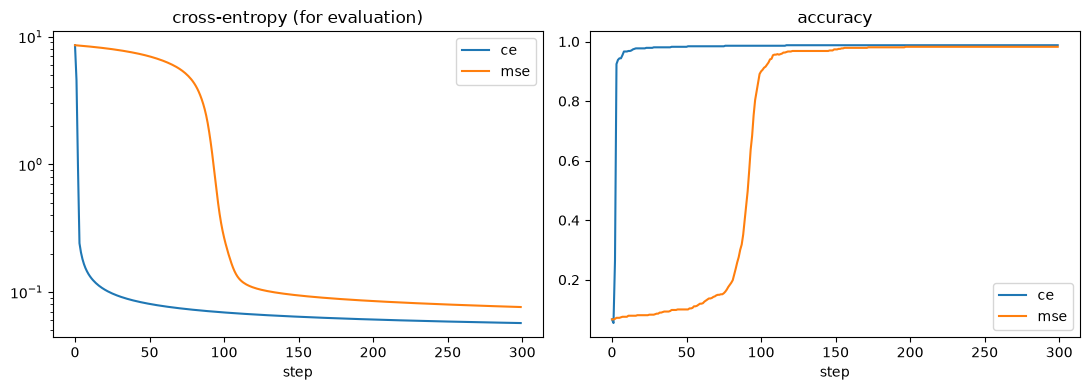

**해 보기**: `w_wrong` 대신 `np.zeros(n)` (반반에서 출발) 으로 바꿔 보자. 이때도 차이가 클까? 슬라이드의 기울기 그림에서 $\hat y = 0.5$ 근처의 두 곡선을 비교해 보자.

## 파트 3. 셰익스피어: 다음 글자에 칩 나눠 걸기

언어 모델은 다음 글자(단어)에 칩을 나눠 걸고, 실제 다음 글자에 건 비율로 벌점을 받는다. 처음 실행하면 글 파일(약 1MB)을 내려받는다.
- 모델 1: 모든 글자에 **고르게** 건다
- 모델 2: 앞 글자를 보고, 학습 글에서 **세어 본** 비율대로 건다 (bigram)

In [ ]:
import urllib.request
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/shakespeare.txt"):
    urllib.request.urlretrieve(url, "data/shakespeare.txt")
text = open("data/shakespeare.txt").read()
chars = sorted(set(text)); V = len(chars); idx = {c: i for i, c in enumerate(chars)}
cut = int(len(text) * 0.9)
train_txt, test_txt = text[:cut], text[cut:]
print(f"{len(text):,} characters, {V} distinct")
print(test_txt[:200])

**예상 결과**

```
1,115,394 characters, 65 distinct
?

GREMIO:
Good morrow, neighbour Baptista.

BAPTISTA:
Good morrow, neighbour Gremio.
God save you, gentlemen!

PETRUCHIO:
And you, good sir! Pray, have you not a daughter
Call'd Katharina, fair and v
```

In [ ]:
# Model 1: uniform -> every character gets 1/V
uniform_bits = penalty_bits(1 / V)
print(f"uniform bet: {uniform_bits:.2f} bits per character")

# Model 2: share = count of b right after a (+1 smoothing)
counts = np.ones((V, V))
for a, b in zip(train_txt, train_txt[1:]):
    counts[idx[a], idx[b]] += 1
q = counts / counts.sum(1, keepdims=True)                 # q[a, b] = share bet on b after a

pairs = np.array([(idx[a], idx[b]) for a, b in zip(test_txt, test_txt[1:])])
bits = None   # TODO: penalties for the share bet on the actual next character
print(f"counted bet: {bits.mean():.2f} bits per character on average")

**예상 결과**

```
uniform bet: 6.02 bits per character
counted bet: 3.58 bits per character on average
```

In [ ]:
# Where does it bet after 'q'? (in English, q is almost always followed by u)
top = np.argsort(q[idx['q']])[::-1][:3]
for t in top:
    print(repr(chars[t]), f"{q[idx['q'], t]:.0%}")

**예상 결과**

```
'u' 90%
'z' 0%
'K' 0%
```

**확인 질문**
1. 파트 1 에서 정답에 0 을 건 샘플이 하나라도 있으면 평균 교차 엔트로피는? `binary_ce` 에 넣어 보자 (그래서 실전 코드는 `clip` 을 한다).
2. 파트 2 에서 MSE 가 확신하고 틀린 출발점에서 느린 이유를 슬라이드의 기울기 식으로 설명해 보자.
3. 파트 3 의 고르게 걸기 벌점이 왜 $\log_2 V$ 인가?
4. 파트 3 에서 앞 글자 두 개를 보고 세면(trigram) 벌점은 더 줄어들까? 학습 글에 한 번도 안 나온 조합은 어떻게 될까?

데이터 출처: Wolberg et al., Breast Cancer Wisconsin (Diagnostic), UCI (scikit-learn) · Tiny Shakespeare, Karpathy char-rnn.